<a href="https://colab.research.google.com/github/leovarconrenno/Estacao-de-Reabastecimento-de-Hidrogenio---SCADA-Core/blob/main/etapa-03-arvores/Aula%2019%20-%20Algoritmo%20de%20Kruskal%20e%20Prim%20-%20code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 19 - Notebook: Kruskal e Prim nos Setores 100, 200 e 300 da HRS (SCADA H₂)

Este notebook calcula a **Árvore Geradora Mínima (MST)** para interligação física dos equipamentos reais da Estação de Reabastecimento de Hidrogênio (`SUP-100`, `TK-101`, `TK-102`, `TK-103`, `XV-104`, `HEX-201`, `DISP-300`, `SCADA-01`) usando **Kruskal** (*Union-Find*) e **Prim** (*Min-Heap*).

In [1]:
from typing import List, Tuple, Dict, Set
import heapq
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import networkx as nx
import pandas as pd
from IPython.display import display

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

In [2]:
class DisjointSet:
    def __init__(self, vertices: List[str]):
        self.parent = {v: v for v in vertices}
        self.rank = {v: 0 for v in vertices}

    def find(self, x: str) -> str:
        if self.parent[x] != x:
            self.parent[x] = self.find(self.parent[x])
        return self.parent[x]

    def union(self, a: str, b: str) -> bool:
        ra, rb = self.find(a), self.find(b)
        if ra == rb:
            return False
        if self.rank[ra] < self.rank[rb]:
            self.parent[ra] = rb
        elif self.rank[ra] > self.rank[rb]:
            self.parent[rb] = ra
        else:
            self.parent[rb] = ra
            self.rank[ra] += 1
        return True

def kruskal_mst(vertices: List[str], edges: List[Tuple[str, str, float]]):
    dsu = DisjointSet(vertices)
    mst, total, log = [], 0.0, []
    for u, v, w in sorted(edges, key=lambda e: e[2]):
        if dsu.union(u, v):
            mst.append((u, v, w))
            total += w
            log.append({"Aresta": f"{u} <-> {v}", "Peso (m)": w, "Decisão": "INCLUÍDA"})
        else:
            log.append({"Aresta": f"{u} <-> {v}", "Peso (m)": w, "Decisão": "REJEITADA (Ciclo)"})
        if len(mst) == len(vertices) - 1:
            break
    return mst, total, pd.DataFrame(log)

def prim_mst(vertices: List[str], edges: List[Tuple[str, str, float]], start: str = "SCADA-01"):
    adj = {v: [] for v in vertices}
    for u, v, w in edges:
        adj[u].append((w, v))
        adj[v].append((w, u))
    visitados = {start}
    heap = [(w, start, nb) for w, nb in adj[start]]
    heapq.heapify(heap)
    mst, total, log = [], 0.0, []
    while heap and len(visitados) < len(vertices):
        w, u, v = heapq.heappop(heap)
        if v in visitados:
            continue
        visitados.add(v)
        mst.append((u, v, w))
        total += w
        log.append({"Aresta": f"{u} -> {v}", "Peso (m)": w, "Nó Adicionado": v})
        for nw, nb in adj[v]:
            if nb not in visitados:
                heapq.heappush(heap, (nw, v, nb))
    return mst, total, pd.DataFrame(log)

In [3]:
nodes = ["SUP-100", "TK-101", "TK-102", "TK-103", "XV-104", "HEX-201", "DISP-300", "SCADA-01"]
edges = [
    ("TK-102", "XV-104", 6.0),
    ("TK-101", "XV-104", 8.0),
    ("TK-103", "XV-104", 8.0),
    ("XV-104", "HEX-201", 9.0),
    ("SUP-100", "TK-101", 10.0),
    ("HEX-201", "DISP-300", 11.0),
    ("SUP-100", "TK-102", 12.0),
    ("SCADA-01", "HEX-201", 14.0),
    ("SUP-100", "TK-103", 15.0),
    ("TK-101", "TK-102", 16.0),
    ("SCADA-01", "SUP-100", 18.0),
    ("SCADA-01", "DISP-300", 22.0),
    ("TK-103", "HEX-201", 17.0),
]

k_mst, k_w, df_k = kruskal_mst(nodes, edges)
p_mst, p_w, df_p = prim_mst(nodes, edges, start="SCADA-01")
print(f"Comprimento MST (Kruskal): {k_w:.1f} m | (Prim): {p_w:.1f} m | Iguais: {k_w == p_w}")
display(df_k)
display(df_p)

Comprimento MST (Kruskal): 66.0 m | (Prim): 66.0 m | Iguais: True


,Aresta,Peso (m),Decisão
0,TK-102 <-> XV-104,6.0,INCLUÍDA
1,TK-101 <-> XV-104,8.0,INCLUÍDA
2,TK-103 <-> XV-104,8.0,INCLUÍDA
3,XV-104 <-> HEX-201,9.0,INCLUÍDA
4,SUP-100 <-> TK-101,10.0,INCLUÍDA
5,HEX-201 <-> DISP-300,11.0,INCLUÍDA
6,SUP-100 <-> TK-102,12.0,REJEITADA (Ciclo)
7,SCADA-01 <-> HEX-201,14.0,INCLUÍDA


,Aresta,Peso (m),Nó Adicionado
0,SCADA-01 -> HEX-201,14.0,HEX-201
1,HEX-201 -> XV-104,9.0,XV-104
2,XV-104 -> TK-102,6.0,TK-102
3,XV-104 -> TK-101,8.0,TK-101
4,XV-104 -> TK-103,8.0,TK-103
5,TK-101 -> SUP-100,10.0,SUP-100
6,HEX-201 -> DISP-300,11.0,DISP-300


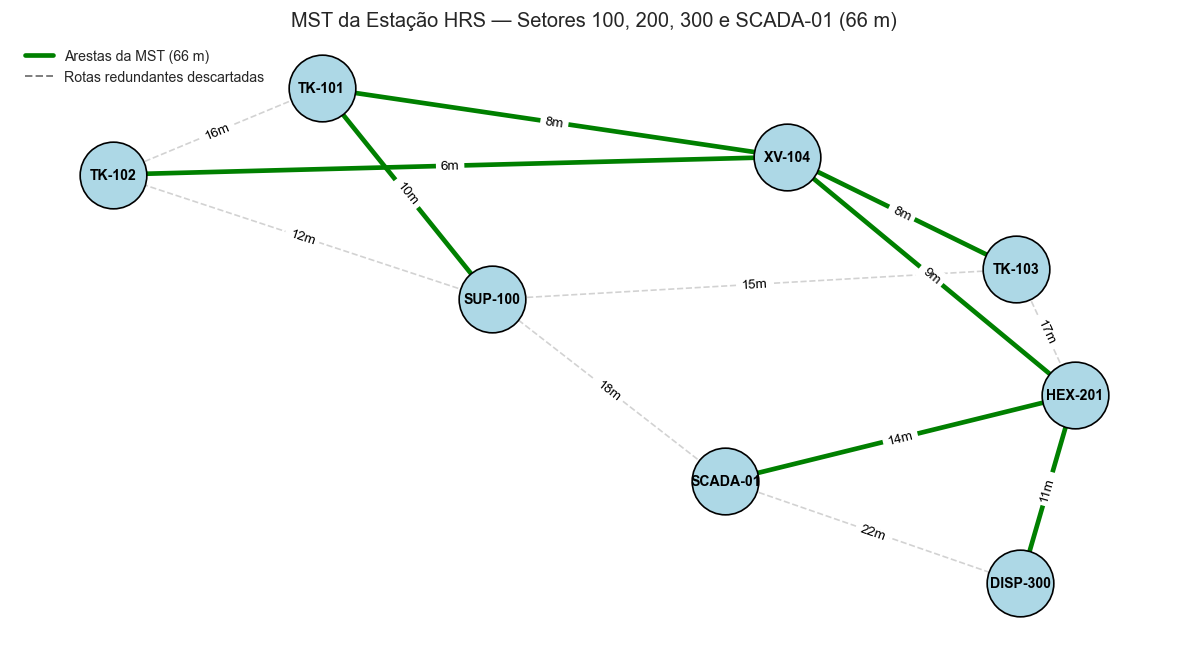

In [4]:
G = nx.Graph()
for u, v, w in edges:
    G.add_edge(u, v, weight=w)
pos = nx.spring_layout(G, seed=42, k=1.2)
fig, ax = plt.subplots(figsize=(10, 5.5))
nx.draw_networkx_edges(G, pos, ax=ax, edgelist=edges, style="dashed", alpha=0.35, edge_color="gray")
nx.draw_networkx_edges(G, pos, ax=ax, edgelist=k_mst, width=2.8, edge_color="green")
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=1600, node_color="lightblue", edgecolors="black")
nx.draw_networkx_labels(G, pos, ax=ax, font_size=8.5, font_weight="bold")
nx.draw_networkx_edge_labels(G, pos, ax=ax, edge_labels={(u, v): f"{w:.0f}m" for u, v, w in edges}, font_size=8)
legenda = [
    Line2D([0], [0], color="green", lw=2.8, label="Arestas da MST (66 m)"),
    Line2D([0], [0], color="gray", lw=1.2, linestyle="--", label="Rotas redundantes descartadas"),
]
ax.legend(handles=legenda, loc="upper left", fontsize=8.5)
ax.set_title("MST da Estação HRS — Setores 100, 200, 300 e SCADA-01 (66 m)")
ax.axis("off")
plt.tight_layout()
plt.show()